In [1]:
%pip install pandas numpy matplotlib seaborn plotly

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

In [3]:
df_dock = pd.read_csv("dockstring-dataset.tsv", sep="\t")


df_dock.head()

df_dock.columns

Index(['inchikey', 'smiles', 'PPARD', 'ABL1', 'ADAM17', 'ADRB1', 'ADRB2',
       'AKT2', 'MAOB', 'CASP3', 'DHFR', 'ESR2', 'PTK2', 'FGFR1', 'HMGCR',
       'HSP90AA1', 'KIT', 'MAPKAPK2', 'MAP2K1', 'NOS1', 'PARP1', 'PDE5A',
       'PGR', 'PTPN1', 'ROCK1', 'AKT1', 'AR', 'CDK2', 'CSF1R', 'ESR1', 'NR3C1',
       'IGF1R', 'JAK2', 'LCK', 'MET', 'MMP13', 'PTGS2', 'PPARA', 'PPARG',
       'REN', 'ADORA2A', 'ACHE', 'BACE1', 'CA2', 'CYP2C9', 'CYP3A4', 'HSD11B1',
       'DPP4', 'DRD2', 'DRD3', 'EGFR', 'F10', 'GBA', 'MAPK1', 'MAPK14', 'PLK1',
       'SRC', 'THRB', 'F2', 'KDR'],
      dtype='object')

In [4]:
df_dock[["JAK2"]].describe()

,JAK2
count,260153.000000
mean,-8.410401
std,0.971447
min,-13.700000
25%,-9.000000
50%,-8.400000
75%,-7.800000
max,-4.000000


In [5]:
df_dock[["LCK"]].describe()

,LCK
count,260151.000000
mean,-8.047818
std,0.947048
min,-13.600000
25%,-8.700000
50%,-8.100000
75%,-7.400000
max,-3.800000


In [6]:
df = pd.read_csv("data/experiment_history.csv")

# Display all columns
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Dataset shape:", df.shape)
print("Number of molecules:", len(df))
print("Number of iterations:", df["iteration"].nunique())

display(df.head())

Dataset shape: (491, 10)
Number of molecules: 491
Number of iterations: 23


,iteration,smiles,qed,predicted_jak2,predicted_lck,combined_score,passes_filters,docking_jak2,docking_lck,jak2_objective
0,1,Nc1nccc(C(=O)Nc2ccc(F)c(CN3CCOCC3)c2)n1,0.876585,-8.748392,-8.062404,7.144642,False,NaN,NaN,NaN
1,1,Cc1ccc2[nH]c(Nc3nccnc3C(=O)N3CCN(C)CC3)cc2c1,0.758434,-9.740760,-8.587827,6.944984,False,NaN,NaN,NaN
2,1,CN1CCN(C(=O)c2sccc2Nc2ccnc(N)n2)CC1,0.885511,-7.680205,-7.175935,6.832469,False,NaN,NaN,NaN
3,1,CN1CCN(C(=O)c2ccc(Nc3cc(N)cnn3)nc2)CC1,0.854774,-8.116766,-7.625328,6.807186,False,NaN,NaN,NaN
4,1,CN1CCN(C(=O)c2ccc(Nc3csc(N)n3)nc2)CC1,0.885511,-7.714578,-7.467547,6.791333,False,NaN,NaN,NaN


In [7]:
# Convert numerical columns
numeric_cols = [
    "iteration",
    "qed",
    "predicted_jak2",
    "predicted_lck",
    "combined_score",
    "docking_jak2",
    "docking_lck",
    "jak2_objective"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert filter column to Boolean
df["passes_filters"] = (
    df["passes_filters"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"true": True, "false": False})
)

# Create a shorter molecule identifier
df["molecule_id"] = ["Molecule " + str(i+1) for i in range(len(df))]

df_all = df.copy()

df_unique = df_all.drop_duplicates(
    subset="smiles"
).copy()

print("Cleaned dataset:", df.shape)
print("Docked JAK2 molecules:", df["docking_jak2"].notna().sum())
print("Docked LCK molecules:", df["docking_lck"].notna().sum())

Cleaned dataset: (491, 11)
Docked JAK2 molecules: 163
Docked LCK molecules: 163


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Simple color palette
blue = "#527A91"
red = "#C44E52"
gray = "#999999"
black = "#222222"

# Set visualization style
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["axes.titleweight"] = "normal"
plt.rcParams["axes.titlesize"] = 17
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["grid.color"] = "#E5E5E5"
plt.rcParams["grid.linewidth"] = 0.7

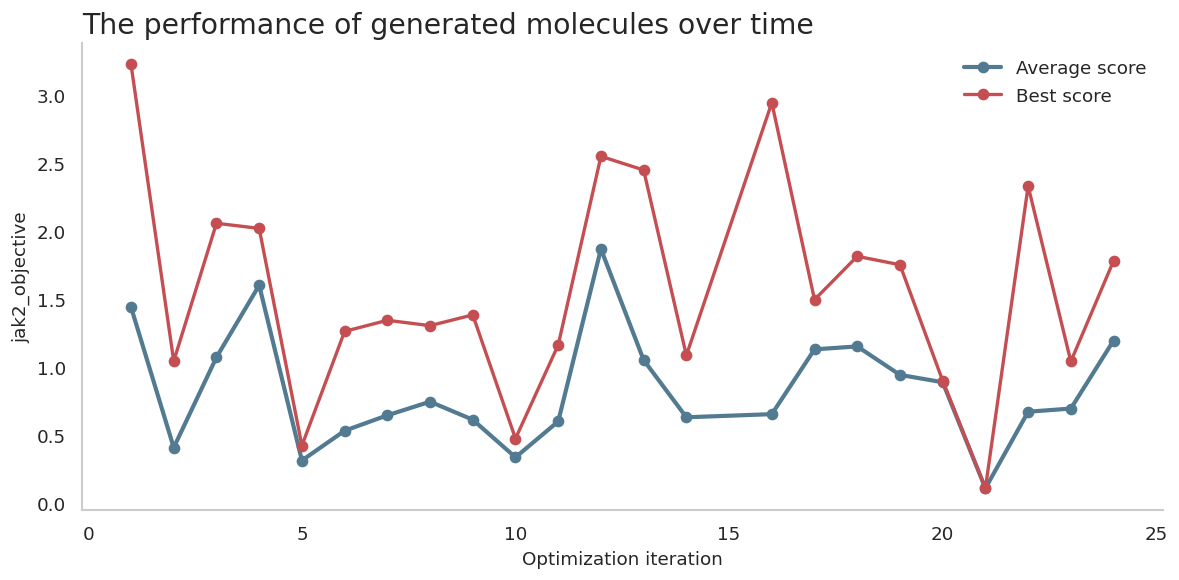

In [18]:
# Calculate average and maximum scores per iteration
iteration_stats = df_all.groupby("iteration")["jak2_objective"].agg(
    ["mean", "max"]
).reset_index()

plt.figure(figsize=(10, 5))

plt.plot(
    iteration_stats["iteration"],
    iteration_stats["mean"],
    marker="o",
    color=blue,
    linewidth=2.5,
    label="Average score"
)

plt.plot(
    iteration_stats["iteration"],
    iteration_stats["max"],
    marker="o",
    color=red,
    linewidth=2,
    label="Best score"
)

plt.title("The performance of generated molecules over time", loc="left")
plt.xlabel("Optimization iteration")
plt.ylabel("jak2_objective")

plt.legend(frameon=False)
plt.grid(axis="y")
plt.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

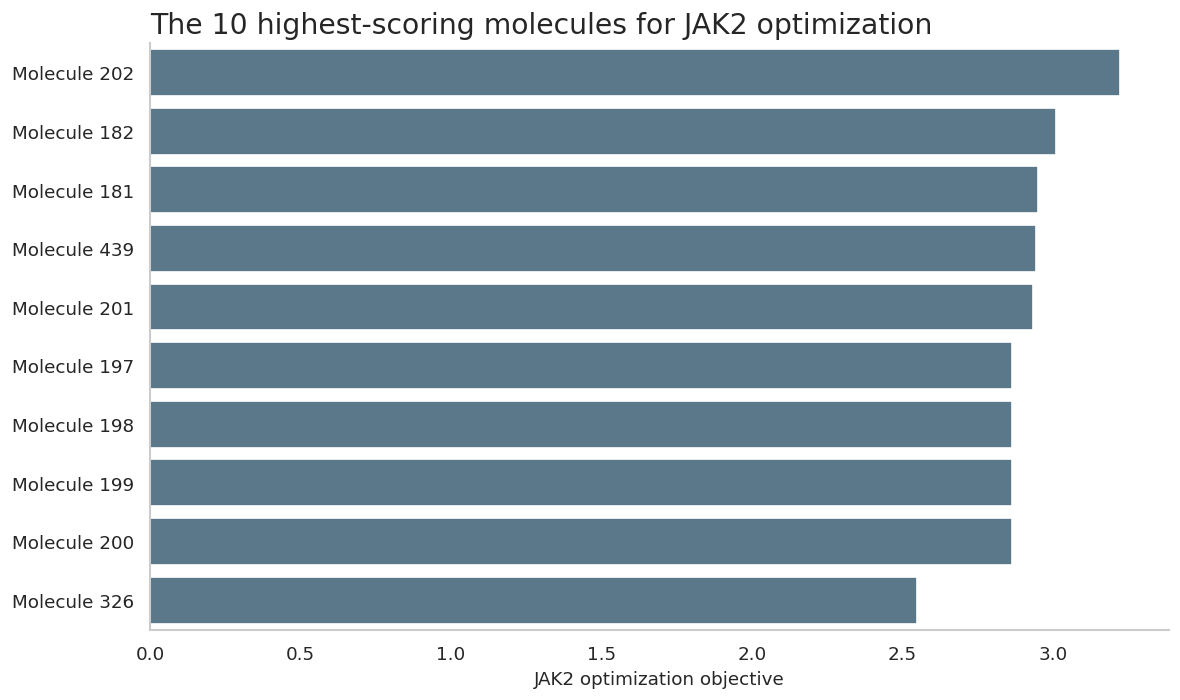

In [16]:
top_molecules = df_all.nlargest(10, "jak2_objective").copy()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_molecules,
    x="jak2_objective",
    y="molecule_id",
    color=blue
)

plt.title("The 10 highest-scoring molecules for JAK2 optimization", loc="left")
plt.xlabel("JAK2 optimization objective")
plt.ylabel("")

plt.grid(axis="y", visible=False)
plt.grid(axis="x")

plt.tight_layout()
plt.show()

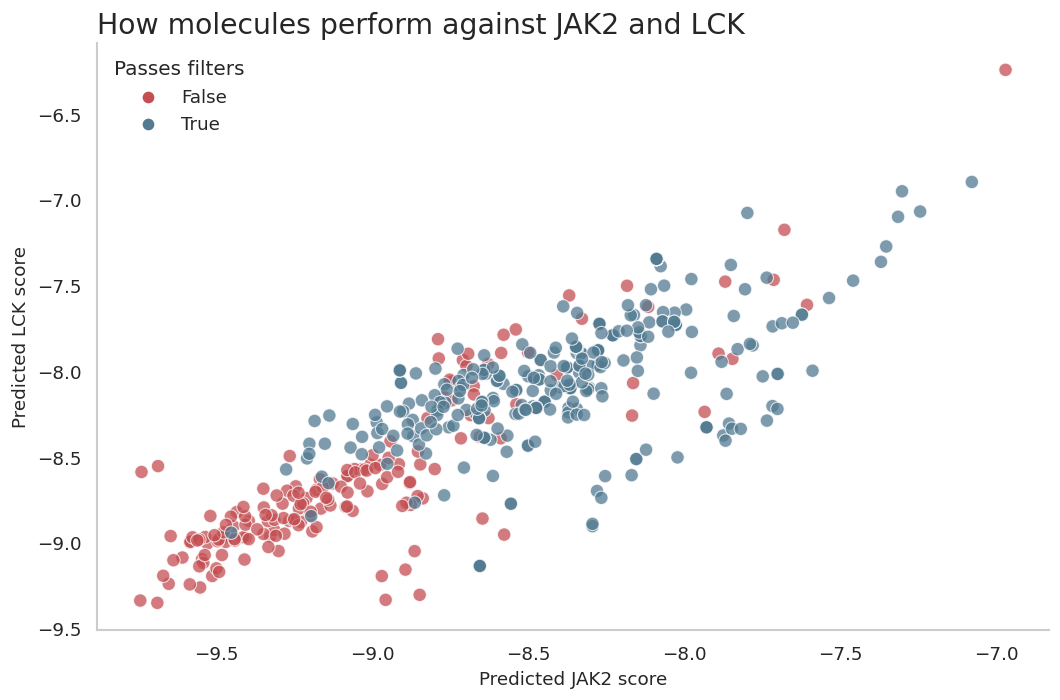

In [10]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_all,
    x="predicted_jak2",
    y="predicted_lck",
    hue="passes_filters",
    palette={True: blue, False: red},
    alpha=0.75,
    s=65
)

plt.title("How molecules perform against JAK2 and LCK", loc="left")
plt.xlabel("Predicted JAK2 score")
plt.ylabel("Predicted LCK score")

plt.legend(title="Passes filters", frameon=False)

plt.grid(axis="y")
plt.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

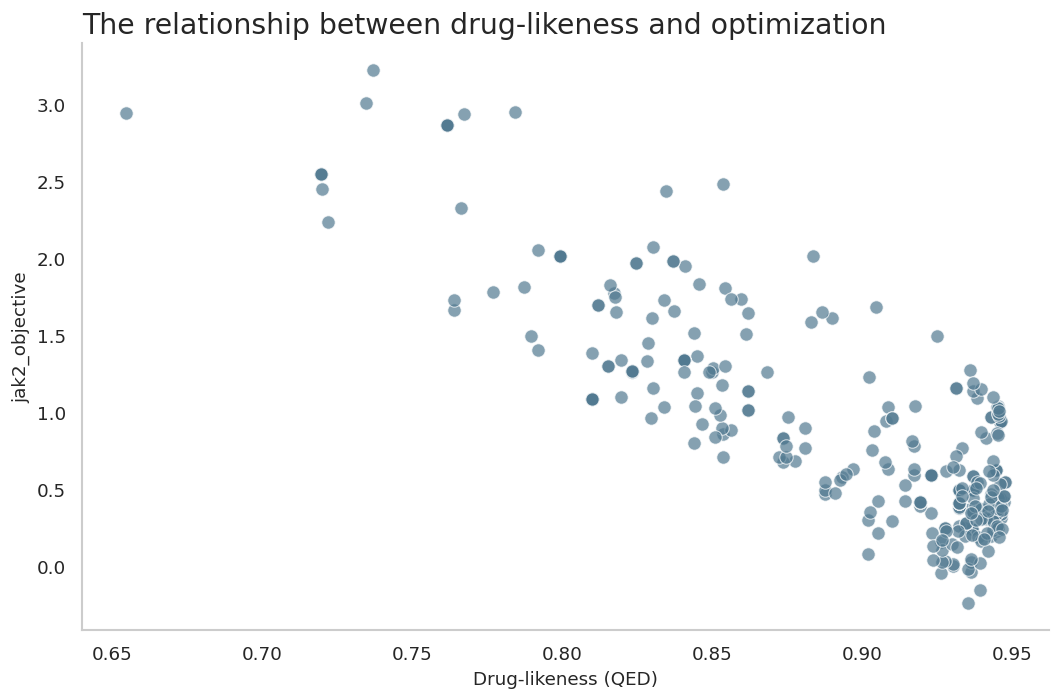

In [19]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_all,
    x="qed",
    y="jak2_objective",
    color=blue,
    alpha=0.7,
    s=65
)

plt.title("The relationship between drug-likeness and optimization", loc="left")
plt.xlabel("Drug-likeness (QED)")
plt.ylabel("jak2_objective")

plt.grid(axis="y")
plt.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

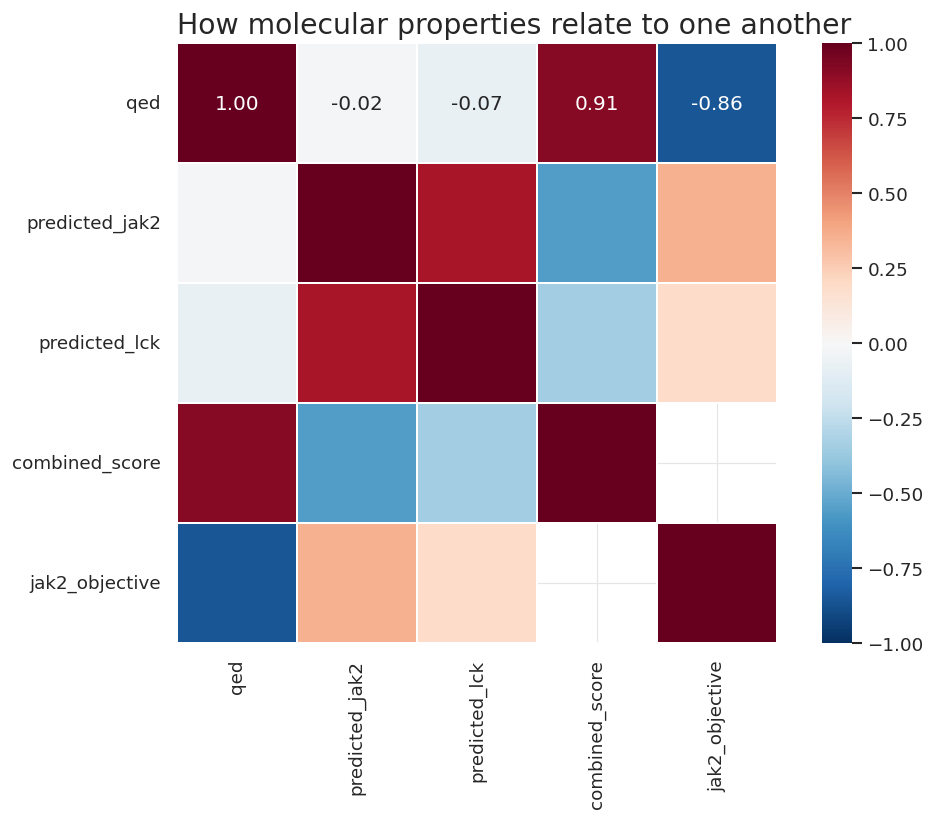

In [12]:
columns = [
    "qed",
    "predicted_jak2",
    "predicted_lck",
    "combined_score",
    "jak2_objective"
]

correlation = df_all[columns].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=1,
    square=True
)

plt.title("How molecular properties relate to one another", loc="left")

plt.tight_layout()
plt.show()

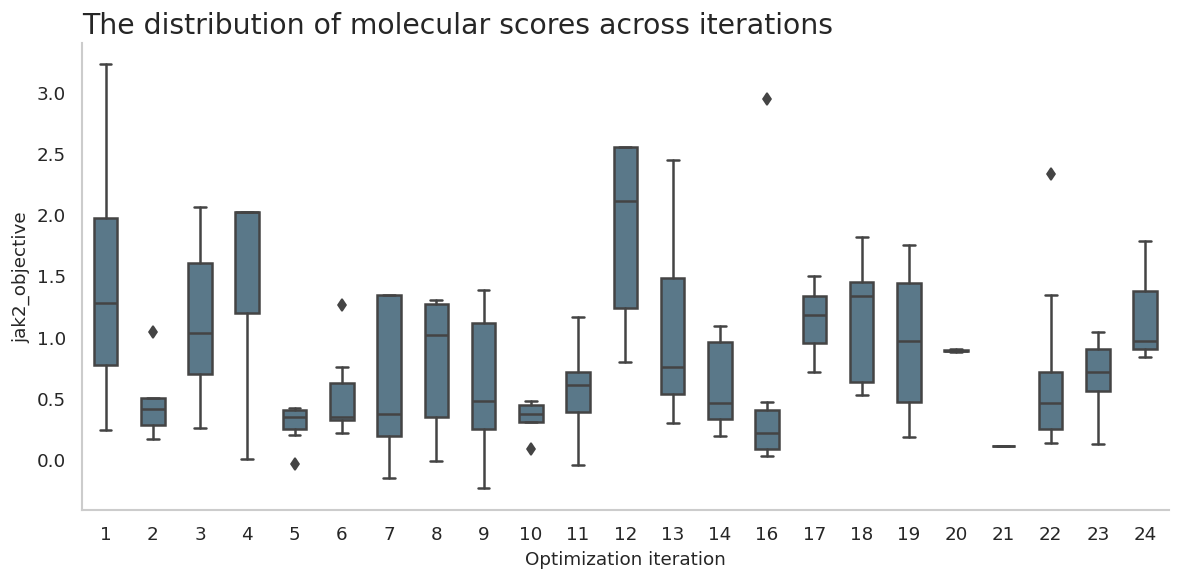

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_all,
    x="iteration",
    y="jak2_objective",
    color=blue,
    width=0.5
)

plt.title("The distribution of molecular scores across iterations", loc="left")
plt.xlabel("Optimization iteration")
plt.ylabel("jak2_objective")

plt.grid(axis="y")
plt.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

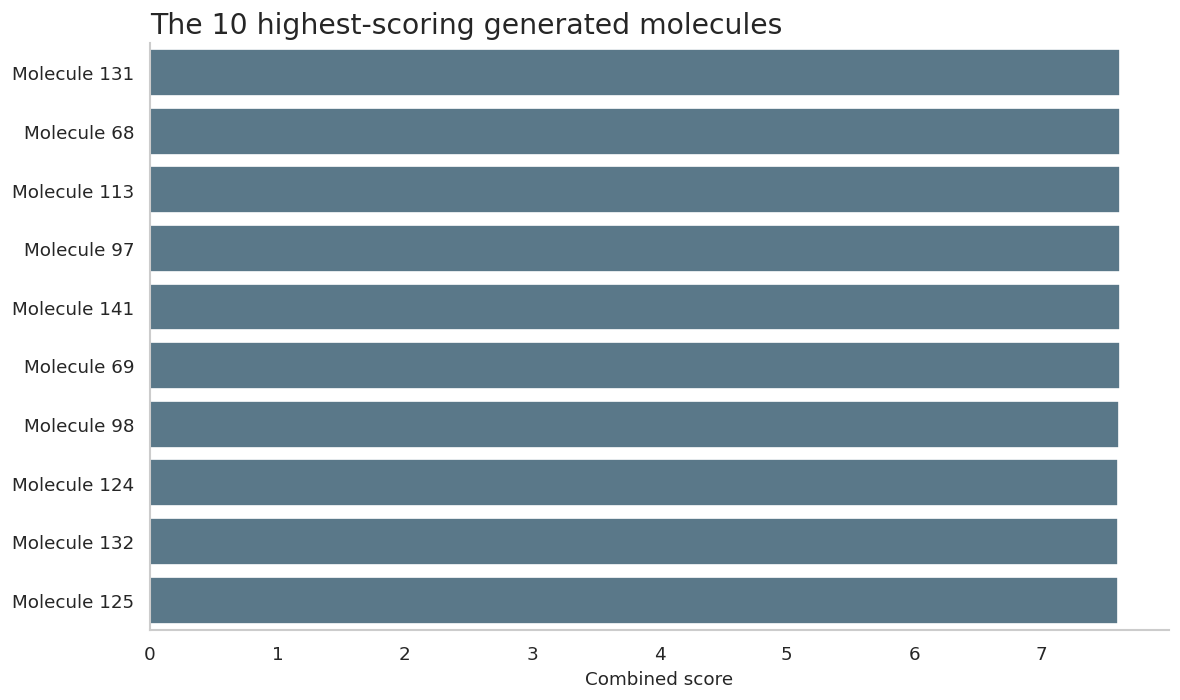

In [14]:
top_molecules = df_all.nlargest(10, "combined_score").copy()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_molecules,
    x="combined_score",
    y="molecule_id",
    color=blue
)

plt.title("The 10 highest-scoring generated molecules", loc="left")
plt.xlabel("Combined score")
plt.ylabel("")

plt.grid(axis="y", visible=False)
plt.grid(axis="x")

plt.tight_layout()
plt.show()

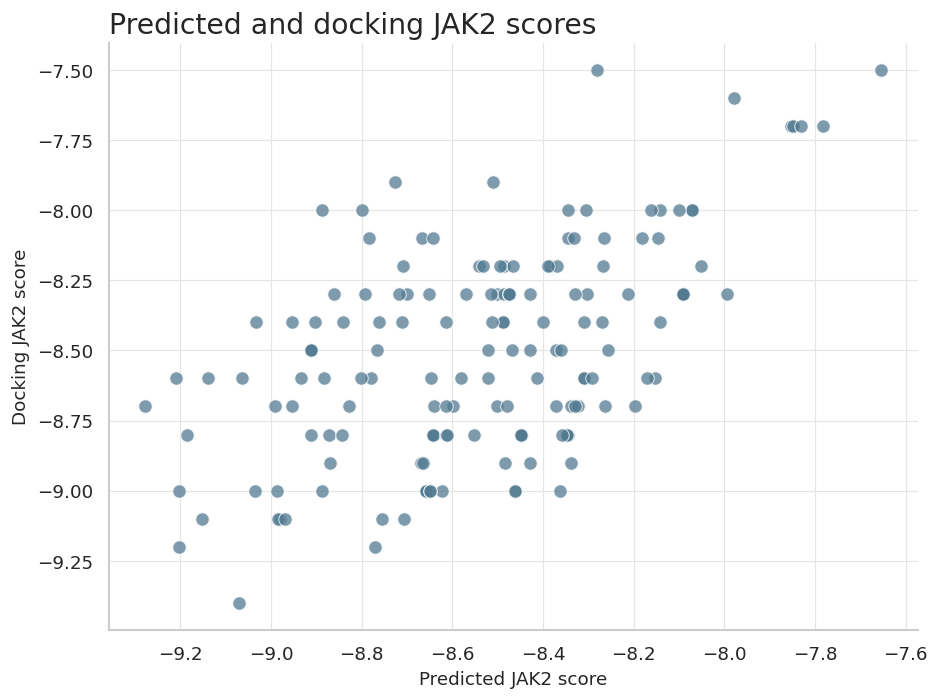

In [15]:
docked = df_all.dropna(
    subset=["predicted_jak2", "docking_jak2"]
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=docked,
    x="predicted_jak2",
    y="docking_jak2",
    color=blue,
    s=65,
    alpha=0.75
)

plt.title("Predicted and docking JAK2 scores", loc="left")
plt.xlabel("Predicted JAK2 score")
plt.ylabel("Docking JAK2 score")

plt.tight_layout()
plt.show()